# Base ECLYPSE vs ECLYPSE+NET: analysis of the comparison

This notebook analyses the results of `main.py`, which simulates every scenario twice:
once with base ECLYPSE (`Infrastructure` and `Application`) and once with ECLYPSE+NET
(`Network` and `NetworkApplication`). The two simulations of a scenario have the same
graphs, the same placement and the same update policies:

- **infrastructure**: the bandwidth of the links fluctuates at every step, and some
  router links periodically go down and come back (`LinkFailures`);
- **application**: the packet rate of the flows follows a daily cycle, and their packet
  size changes every few steps.

Base ECLYPSE does not generate packets and does not route them: at every step it only
checks the placement (`enact`) and applies the update policies (`policies`).
ECLYPSE+NET also runs the packet generation (`generation`) and forwards the packets by
one hop (`routing`). Every phase is timed at every step.

`main.py` saves one row per simulation in `results.csv` and one row per step in
`steps.csv`, by default in `~/eclypse-sim/eclypse_comparison/`. Every chart shows the
mean over the seeds; the shaded band, where present, spans the minimum and the maximum.

## Setup

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

RESULTS = Path(os.environ.get(
    "ECLYPSE_COMPARISON_RESULTS", Path.home() / "eclypse-sim" / "eclypse_comparison"
))
df = pd.read_csv(RESULTS / "results.csv")
steps = pd.read_csv(RESULTS / "steps.csv")

SCENARIO = ["topology", "routers", "seed"]
TOPOLOGIES = {
    "internet_as": "Internet AS graph",
    "scale_free": "Barabási–Albert",
    "random": "Erdős–Rényi",
}
TOPOLOGIES = {t: label for t, label in TOPOLOGIES.items() if t in set(df["topology"])}
MODES = {
    "base": {"label": "ECLYPSE", "color": "#2a78d6", "marker": "o"},
    "net": {"label": "ECLYPSE+NET", "color": "#eb6834", "marker": "s"},
}
PHASES = {
    "enact": {"label": "placement check (enact)", "color": "#2a78d6"},
    "policies": {"label": "update policies", "color": "#1baf7a"},
    "generation": {"label": "packet generation", "color": "#eda100"},
    "routing": {"label": "routing", "color": "#eb6834"},
    "other": {"label": "other", "color": "#b5b3ad"},
}
SIZES = sorted(int(s) for s in df["routers"].unique())

# Per-step times, in milliseconds
for phase in PHASES:
    df[f"{phase}_ms_per_step"] = df[f"{phase}_time_s"] / df["steps_run"] * 1000
df["sim_ms_per_step"] = df["sim_time_s"] / df["steps_run"] * 1000

# Chart style: light surface, recessive axes and grid
SURFACE, TEXT, TEXT_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_MUTED,
    "axes.titlecolor": TEXT,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "legend.frameon": False,
    "legend.labelcolor": TEXT,
    "font.size": 10,
})


def over_seeds(data, y):
    # Mean, minimum and maximum of `y` over the seeds, for each mode, topology and size
    return (data.groupby(["mode", "topology", "routers"])[y]
            .agg(["mean", "min", "max"]).reset_index())


def size_axis(ax):
    # Logarithmic axis of the number of routers, labelled with the sizes of the grid
    ax.set_xscale("log", base=2)
    ax.set_xticks(SIZES, [str(s) for s in SIZES])
    ax.minorticks_off()
    ax.set_xlabel("routers")


print(f"{len(df)} simulations: {df.groupby('mode').size().to_dict()}")
print(f"topologies: {list(TOPOLOGIES)}, routers: {SIZES}, "
      f"seeds: {sorted(df['seed'].unique().tolist())}")

72 simulations: {'base': 36, 'net': 36}
topologies: ['internet_as', 'scale_free', 'random'], routers: [64, 128, 256, 512], seeds: [3997, 151195, 300425]


## 1. The scenarios

Size of the scenarios, averaged over the seeds, and the number of link failures caused
by `LinkFailures` during the simulation.

The two modes must evolve in the same way: the policies draw the same random numbers
from the same seed and change the same values. The check below compares, for every
scenario, the state left by the policies in the two modes: number of links, sum of the
link bandwidths, sum of the packet rates and of the packet sizes of the flows.

In [2]:
scenarios = (df[df["mode"] == "net"]
             .groupby(["topology", "routers"])
             [["n_hosts", "n_links", "n_flows", "link_failures"]]
             .mean().round(1))
print(scenarios.to_string())

END = ["end_links", "end_bandwidth_sum", "end_rate_sum", "end_size_sum"]
paired = df.pivot_table(index=SCENARIO, columns="mode", values=END)
same = pd.DataFrame(
    {c: np.isclose(paired[(c, "base")], paired[(c, "net")], rtol=1e-9) for c in END},
    index=paired.index,
)
print()
print(f"Scenarios with the same final state in both modes: {int(same.all(axis=1).sum())}"
      f" of {len(same)}")

                     n_hosts  n_links  n_flows  link_failures
topology    routers                                          
internet_as 64          48.7    144.7    100.0           10.0
            128        103.7    288.3    100.0           20.0
            256        212.7    573.3    100.0           36.7
            512        429.7   1165.0    100.0           73.3
random      64          64.0    252.7    100.0           20.0
            128        128.0    597.0    100.0           46.7
            256        256.0   1304.3    100.0          105.0
            512        512.0   2901.0    100.0          238.3
scale_free  64          64.0    188.0    100.0           10.0
            128        128.0    380.0    100.0           25.0
            256        256.0    764.0    100.0           50.0
            512        512.0   1532.0    100.0          100.0

Scenarios with the same final state in both modes: 36 of 36


## 2. Execution time

Wall-clock time of the whole simulation (from `sim.start()` to the end of
`sim.wait()`), per step, against the number of routers, on log-log axes.

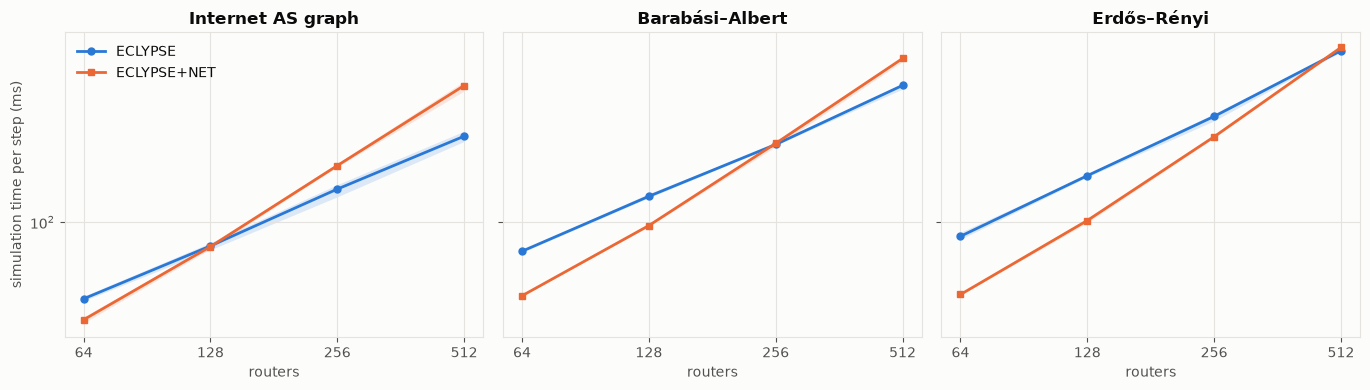

mode                  base    net  net / base
topology    routers                          
internet_as 64        3.98   3.10        0.78
            128       7.51   7.46        0.99
            256      14.86  19.70        1.33
            512      28.03  51.47        1.84
random      64        8.43   4.19        0.50
            128      17.46  10.19        0.58
            256      35.55  27.85        0.78
            512      78.18  81.30        1.04
scale_free  64        7.05   4.13        0.59
            128      13.63   9.60        0.70
            256      25.38  25.72        1.01
            512      51.56  71.21        1.38


In [3]:
stats = over_seeds(df, "sim_ms_per_step")
fig, axes = plt.subplots(1, len(TOPOLOGIES), figsize=(4.6 * len(TOPOLOGIES), 4),
                         sharey=True, squeeze=False)
for ax, (topology, title) in zip(axes[0], TOPOLOGIES.items()):
    for mode, style in MODES.items():
        s = stats[(stats["mode"] == mode) & (stats["topology"] == topology)]
        ax.plot(s["routers"], s["mean"], color=style["color"], marker=style["marker"],
                linewidth=2, markersize=5, label=style["label"])
        ax.fill_between(s["routers"], s["min"], s["max"], color=style["color"],
                        alpha=0.15, linewidth=0)
    ax.set_title(title)
    ax.set_yscale("log")
    size_axis(ax)
axes[0, 0].set_ylabel("simulation time per step (ms)")
axes[0, 0].legend(loc="upper left")
fig.tight_layout()
plt.show()

ratio = df.pivot_table(index=["topology", "routers"], columns="mode",
                       values="sim_time_s", aggfunc="mean")
ratio["net / base"] = ratio["net"] / ratio["base"]
print(ratio.round(2).to_string())

## 3. Where the time goes

Time per step spent in each phase, averaged over the seeds. For each number of routers,
the left bar (`base`) is base ECLYPSE and the right bar (`NET`) ECLYPSE+NET. `generation` and `routing`
are the cost of the packet-level model, which base ECLYPSE does not have.

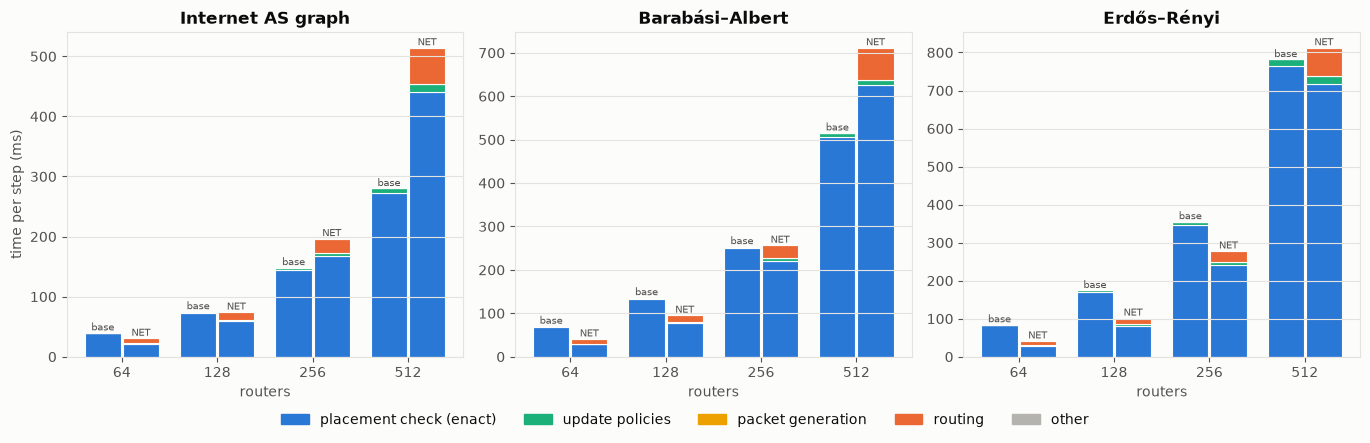

In [4]:
order = list(PHASES)
means = df.groupby(["topology", "routers", "mode"])[
    [f"{p}_ms_per_step" for p in order]
].mean()

fig, axes = plt.subplots(1, len(TOPOLOGIES), figsize=(4.6 * len(TOPOLOGIES), 4.2),
                         squeeze=False)
width = 0.38
for ax, (topology, title) in zip(axes[0], TOPOLOGIES.items()):
    x = np.arange(len(SIZES))
    for offset, mode in ((-width / 2 - 0.01, "base"), (width / 2 + 0.01, "net")):
        bottom = np.zeros(len(SIZES))
        for phase in order:
            values = np.array([means.loc[(topology, s, mode), f"{phase}_ms_per_step"]
                               for s in SIZES])
            ax.bar(x + offset, values, width, bottom=bottom,
                   color=PHASES[phase]["color"], edgecolor=SURFACE, linewidth=0.8)
            bottom += values
        for xi, total in zip(x, bottom):
            ax.text(xi + offset, total, "base" if mode == "base" else "NET",
                    ha="center", va="bottom", fontsize=7, color=TEXT_MUTED)
    ax.set_xticks(x, [str(s) for s in SIZES])
    ax.set_xlabel("routers")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0, 0].set_ylabel("time per step (ms)")
fig.legend(handles=[Patch(color=PHASES[p]["color"], label=PHASES[p]["label"])
                    for p in order],
           loc="lower center", ncol=len(order), bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
plt.show()

The phases common to the two modes do not necessarily cost the same. At every step,
the placement check computes the path of every flow, since the update policies change
the infrastructure and discard the cached paths. Base ECLYPSE computes each path with
the default algorithm (one Dijkstra between the two nodes), while ECLYPSE+NET uses the
`Network` path algorithm: one Dijkstra from each source towards all the nodes, on a
rustworkx copy of the graph built once after every change of the infrastructure. The
two algorithms do different work, so `enact` does not cost the same in the two modes. The table compares the time per step of the common phases
(`enact` and `policies`) and of the packet-level model (`generation` and `routing`),
averaged over topologies and seeds.

In [5]:
share = df.assign(
    common_ms=df["enact_ms_per_step"] + df["policies_ms_per_step"],
    packets_ms=df["generation_ms_per_step"] + df["routing_ms_per_step"],
).pivot_table(index="routers", columns="mode",
              values=["common_ms", "packets_ms", "sim_ms_per_step"], aggfunc="mean")
table = pd.DataFrame({
    "base: common (ms)": share[("common_ms", "base")],
    "net: common (ms)": share[("common_ms", "net")],
    "net: packets (ms)": share[("packets_ms", "net")],
    "common net / base": share[("common_ms", "net")] / share[("common_ms", "base")],
    "packets / net total": share[("packets_ms", "net")] / share[("sim_ms_per_step", "net")],
})
print(table.round(2).to_string())

         base: common (ms)  net: common (ms)  net: packets (ms)  common net / base  packets / net total
routers                                                                                                
64                   64.76             27.34              10.47               0.42                 0.28
128                 128.50             75.32              15.20               0.59                 0.17
256                 252.47            216.61              27.31               0.86                 0.11
512                 525.71            609.99              69.65               1.16                 0.10


## 4. Step by step

Time of each phase at every step, for one scenario: the largest network of the chosen
topology, with the first seed. The grey bands are the steps in which some router links
are down. The bottom panel shows the packets generated at each step by ECLYPSE+NET,
which follow the daily cycle of the application, and the hops simulated.

The routing time peaks at the first step and whenever links go down or come back: the
topology has changed, so `Network` rebuilds its forwarding tables (an all-pairs
Dijkstra). In the other steps, it follows the number of hops to simulate.

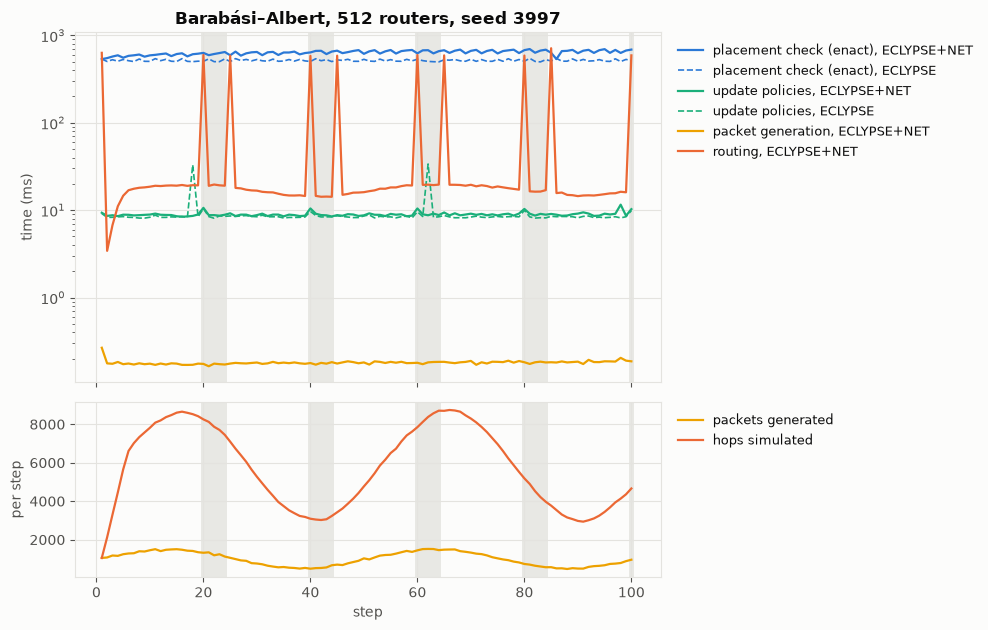

In [6]:
TOPOLOGY = "scale_free" if "scale_free" in TOPOLOGIES else next(iter(TOPOLOGIES))
ROUTERS, SEED = max(SIZES), sorted(df["seed"].unique())[0]
run = steps[(steps["topology"] == TOPOLOGY) & (steps["routers"] == ROUTERS)
            & (steps["seed"] == SEED)].sort_values("step")
base, net = run[run["mode"] == "base"], run[run["mode"] == "net"]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True,
                                  height_ratios=[2, 1])
for ax in (top, bottom):
    down = net["step"][net["links_down"] > 0]
    for s in down:
        ax.axvspan(s - 0.5, s + 0.5, color=GRID, alpha=0.8, linewidth=0)

for phase in ("enact", "policies", "generation", "routing"):
    color = PHASES[phase]["color"]
    top.plot(net["step"], net[f"{phase}_s"] * 1000, color=color, linewidth=1.6,
             label=f"{PHASES[phase]['label']}, ECLYPSE+NET")
    if phase in ("enact", "policies"):
        top.plot(base["step"], base[f"{phase}_s"] * 1000, color=color, linewidth=1.2,
                 linestyle="--", label=f"{PHASES[phase]['label']}, ECLYPSE")
top.set_yscale("log")
top.set_ylabel("time (ms)")
top.set_title(f"{TOPOLOGIES[TOPOLOGY]}, {ROUTERS} routers, seed {SEED}")
top.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)

bottom.plot(net["step"], net["packets"], color="#eda100", linewidth=1.6,
            label="packets generated")
bottom.plot(net["step"], net["hops"], color="#eb6834", linewidth=1.6,
            label="hops simulated")
bottom.set_xlabel("step")
bottom.set_ylabel("per step")
bottom.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
fig.tight_layout()
plt.show()